# Estudo de atributos

## Instalação e imports da bibliotecas

In [3]:
# caso for rodar no google colab
#from google.colab import drive
#drive.mount('/content/drive')

In [4]:
!pip install pandas
!pip install numpy
!pip install duckdb pandas
!pip install matplotlib
!pip install seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import os
import duckdb
import matplotlib.pyplot as plt

In [6]:
os.getcwd()
path = os.getcwd() + "../../../documents/tuca.db"
#pathDrive = os.getcwd() + "/drive/MyDrive/ColabNotebooks/tuca.db"
#path = pathDrive
#path


In [7]:
db = duckdb.connect(path, read_only=True)

dfTransactions = db.execute('SELECT * FROM "transactions"').df()
dfPayers = db.execute('SELECT * FROM "payers"').df()
dfSellers = db.execute('SELECT * FROM "seller_terminals"').df()
print(f"Amostra carregada: {len(dfTransactions):,} transações")
#print(tables)

Amostra carregada: 4,483,956 transações


## Estudo da tabela transações


In [8]:
dfTransactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 4483956 entries, 0 to 4483955
Data columns (total 10 columns):
 #   Column                  Dtype         
---  ------                  -----         
 0   transaction_id          int64         
 1   tx_datetime             datetime64[ns]
 2   tx_date                 datetime64[ns]
 3   tx_time                 str           
 4   tx_amount               float32       
 5   card_id                 int64         
 6   terminal_id             int64         
 7   is_transactional_fraud  int64         
 8   is_fraud                bool          
 9   tx_fraud_report_date    datetime64[ns]
dtypes: bool(1), datetime64[ns](3), float32(1), int64(4), str(1)
memory usage: 329.3 MB


In [9]:
dfTransactions.loc[lambda x: (x["is_transactional_fraud"] == 0) & (x["is_fraud"] == True)]

,transaction_id,tx_datetime,tx_date,tx_time,tx_amount,card_id,terminal_id,is_transactional_fraud,is_fraud,tx_fraud_report_date
2082,2083,2018-01-01 05:02:36,2018-01-01,05:02:36,5.170000,6011176434939411,1133,0,True,2018-01-08
4571,4572,2018-01-01 07:29:57,2018-01-01,07:29:57,83.279999,3577376606259373,1133,0,True,2018-01-09
5688,5689,2018-01-01 08:21:05,2018-01-01,08:21:05,63.740002,6576296029649915,1133,0,True,2018-01-09
7159,7160,2018-01-01 09:24:26,2018-01-01,09:24:26,58.610001,3575399893544929,1133,0,True,2018-01-07
8586,8587,2018-01-01 10:18:19,2018-01-01,10:18:19,8.510000,372624178429020,1133,0,True,2018-01-08
...,...,...,...,...,...,...,...,...,...,...
4482345,4482346,2018-05-31 20:36:56,2018-05-31,20:36:56,30.379999,3598994885669487,1949,0,True,2018-06-08
4482569,4482570,2018-05-31 20:53:56,2018-05-31,20:53:56,99.230003,4029120976589,1649,0,True,2018-06-10
4482640,4482641,2018-05-31 21:00:26,2018-05-31,21:00:26,35.369999,502094127060,1170,0,True,2018-06-10
4482650,4482651,2018-05-31 21:01:21,2018-05-31,21:01:21,34.200001,4945089066036340914,1784,0,True,2018-06-04


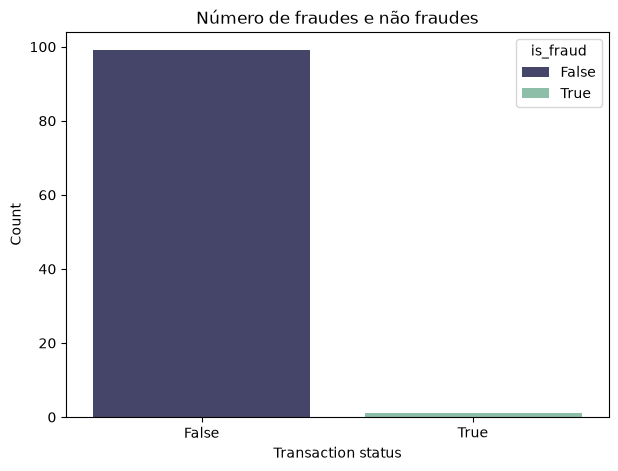

In [10]:

plt.figure(figsize=(7, 5))
sns.countplot(x='is_fraud', data=dfTransactions, palette = ['#3f3e6fd1', '#85c6a9'],hue='is_fraud',stat='percent')
plt.title('Número de fraudes e não fraudes')
plt.xlabel("Transaction status")
plt.ylabel("Count")
plt.show()

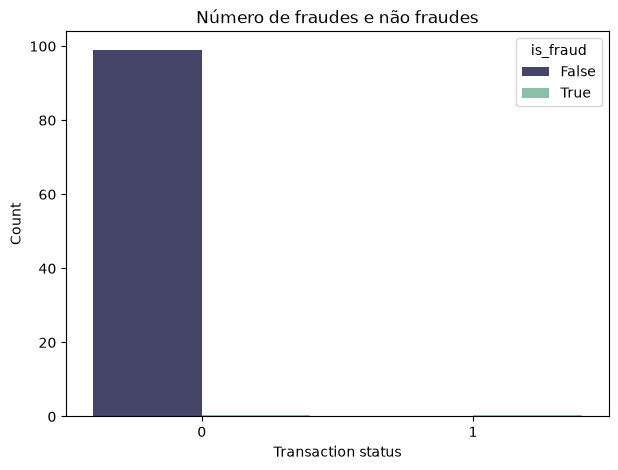

In [11]:

plt.figure(figsize=(7, 5))
sns.countplot(x='is_transactional_fraud', data=dfTransactions, palette = ['#3f3e6fd1', '#85c6a9'],hue='is_fraud',stat='percent')
plt.title('Número de fraudes e não fraudes')
plt.xlabel("Transaction status")
plt.ylabel("Count")
plt.show()

In [12]:
dfVerdadeiras = dfTransactions.loc[lambda x: x["is_fraud"]==True]
dfVerdadeiras["is_fraud"].count()

np.int64(44181)

# Atributos
Atributos de interesse para analise

## Histórico do cartão: taxa de fraude e terminais distintos

O dataframe `dfTransactionsHistorico` acrescenta dois atributos calculados por cartão usando somente transações em instantes estritamente anteriores:

- `card_fraud_rate`: fraudes transacionais, conhecidas no instante da compra, ou fraudes não transacionais cujo reporte já havia ocorrido antes da transação atual, dividido pelo total de transações anteriores do cartão. Sem histórico, fica nulo.
- `card_distinct_terminals`: quantidade de terminais diferentes usados anteriormente pelo cartão. Sem histórico, vale 0.

Transações com o mesmo `tx_datetime` são excluídas em conjunto. Assim, uma compra não usa seu próprio resultado nem o de outra compra simultânea. O rótulo final `is_fraud` só entra na taxa quando a fraude já era observável naquele instante, conforme `tx_fraud_report_date`.


In [13]:
db.register("dfTransactions", dfTransactions)

# O histórico considera apenas instantes estritamente anteriores à transação.
# Fraudes não transacionais só entram na taxa depois de reportadas.
dfTransactionsHistorico = db.execute("""
    WITH historico AS (
        SELECT
            t.*,
            COUNT(*) OVER anteriores AS card_previous_tx_count,
            COUNT(*) FILTER (
                WHERE t.is_transactional_fraud = TRUE
                   OR (
                       t.is_fraud = TRUE
                       AND t.tx_fraud_report_date IS NOT NULL
                       AND t.tx_fraud_report_date < t.tx_datetime
                   )
            ) OVER anteriores AS card_previous_known_fraud_count,
            COUNT(DISTINCT t.terminal_id) OVER anteriores
                AS card_distinct_terminals
        FROM dfTransactions AS t
        WINDOW anteriores AS (
            PARTITION BY t.card_id
            ORDER BY t.tx_datetime
            RANGE BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
            EXCLUDE GROUP
        )
    )
    SELECT
        *,
        card_previous_known_fraud_count::DOUBLE
            / NULLIF(card_previous_tx_count, 0) AS card_fraud_rate
    FROM historico
""").df()

dfTransactionsHistorico.head()


,transaction_id,tx_datetime,tx_date,tx_time,tx_amount,card_id,terminal_id,is_transactional_fraud,is_fraud,tx_fraud_report_date,card_previous_tx_count,card_previous_known_fraud_count,card_distinct_terminals,card_fraud_rate
0,130213,2018-01-06 12:00:00,2018-01-06,12:00:00,13.750000,180051584195510,501,0,False,NaT,20,0,19,0.0
1,139344,2018-01-06 18:40:25,2018-01-06,18:40:25,10.800000,180051584195510,601,0,False,NaT,21,0,20,0.0
2,156163,2018-01-07 13:23:08,2018-01-07,13:23:08,3.090000,180051584195510,948,0,False,NaT,22,0,21,0.0
3,157126,2018-01-07 13:58:33,2018-01-07,13:58:33,17.690001,180051584195510,1129,0,False,NaT,23,0,22,0.0
4,164209,2018-01-07 20:36:25,2018-01-07,20:36:25,23.360001,180051584195510,684,0,False,NaT,24,0,23,0.0


## É um terminal novo (cartão nunca usado antes nesse terminal)

In [14]:
dfNewTerminal = dfTransactions.copy()

dfNewTerminal["dateTime"] = pd.to_datetime(
    dfNewTerminal["tx_datetime"]
)
dfNewTerminal = dfNewTerminal.sort_values("dateTime")

primeiroUso = dfNewTerminal.groupby(
    ["card_id", "terminal_id"]
)["dateTime"].transform("min")

dfNewTerminal["isNewTerminal"] = (
    dfNewTerminal["dateTime"] == primeiroUso
)

dfNewTerminal.head()

,transaction_id,tx_datetime,tx_date,tx_time,tx_amount,card_id,terminal_id,is_transactional_fraud,is_fraud,tx_fraud_report_date,dateTime,isNewTerminal
0,1,2018-01-01 00:00:10,2018-01-01,00:00:10,117.120003,4983922282101,1113,0,False,NaT,2018-01-01 00:00:10,True
1,2,2018-01-01 00:00:38,2018-01-01,00:00:38,57.700001,38435765939628,790,0,False,NaT,2018-01-01 00:00:38,True
2,3,2018-01-01 00:00:38,2018-01-01,00:00:38,41.500000,4053973451359964262,157,0,False,NaT,2018-01-01 00:00:38,True
3,4,2018-01-01 00:00:41,2018-01-01,00:00:41,47.720001,370458387500772,850,0,False,NaT,2018-01-01 00:00:41,True
4,5,2018-01-01 00:01:46,2018-01-01,00:01:46,14.530000,180022431672084,32,0,False,NaT,2018-01-01 00:01:46,True


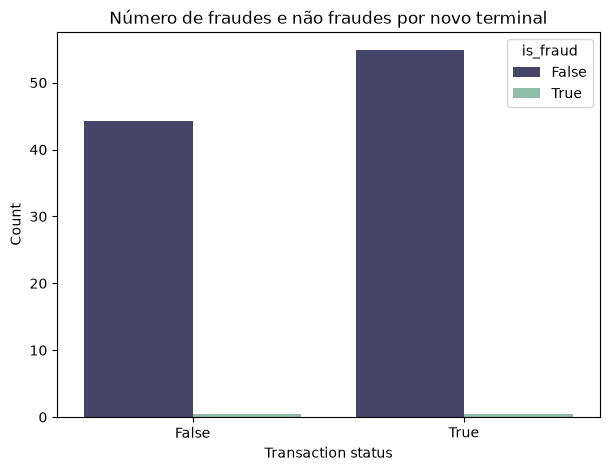

In [15]:
plt.figure(figsize=(7, 5))
sns.countplot(x='isNewTerminal', data=dfNewTerminal, palette = ['#3f3e6fd1', '#85c6a9'],hue='is_fraud',stat='percent')
plt.title('Número de fraudes e não fraudes por novo terminal')
plt.xlabel("Transaction status")
plt.ylabel("Count")
plt.show()

C:\Users\lf446\AppData\Local\Temp\ipykernel_18964\1772027992.py:3: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.countplot(x='isNewTerminal', data=onlyFraude, palette = ['#3f3e6fd1', '#85c6a9'],hue='is_fraud',stat='percent')


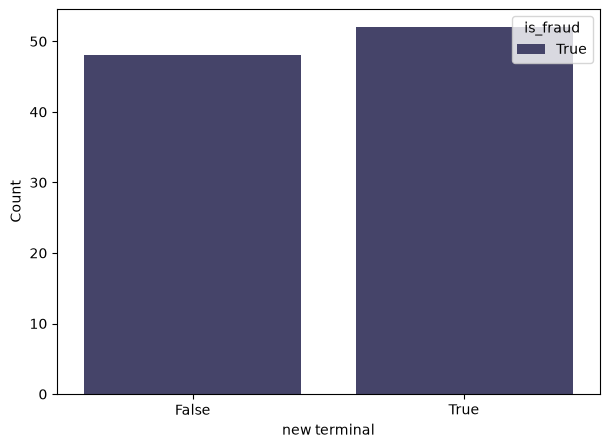

In [16]:
onlyFraude = dfNewTerminal.loc[lambda x: x["is_fraud"]==True]
plt.figure(figsize=(7, 5))
sns.countplot(x='isNewTerminal', data=onlyFraude, palette = ['#3f3e6fd1', '#85c6a9'],hue='is_fraud',stat='percent')
plt.xlabel("new terminal")
plt.ylabel("Count")
plt.show()

C:\Users\lf446\AppData\Local\Temp\ipykernel_18964\2515477521.py:3: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.countplot(x='isNewTerminal', data=onlyFraude, palette = ['#3f3e6fd1', '#85c6a9'],hue='is_fraud',stat='percent')


<Axes: xlabel='isNewTerminal', ylabel='percent'>

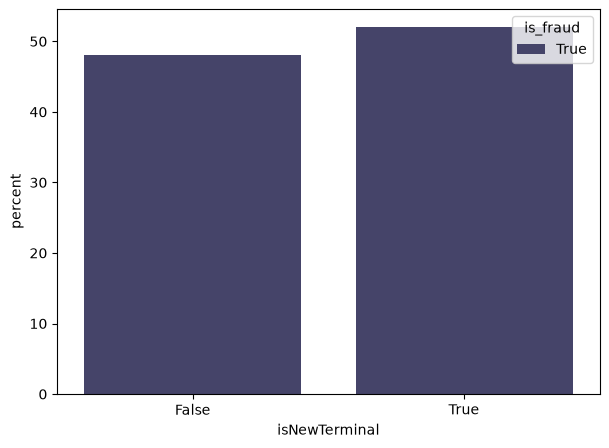

In [17]:
onlyFraude = dfNewTerminal.loc[lambda x: x["is_fraud"]==True]
plt.figure(figsize=(7, 5))
sns.countplot(x='isNewTerminal', data=onlyFraude, palette = ['#3f3e6fd1', '#85c6a9'],hue='is_fraud',stat='percent')

## Campo hora e campo de hora e madrugada

In [18]:
dfCopy = dfTransactions.copy()
dfCopy['hour'] = pd.to_datetime(dfCopy['tx_datetime'], format='%H:%M:%S').dt.hour
dfCopy['dawn'] = dfCopy['hour'].apply(lambda x: 1 if x < 6 else 0)

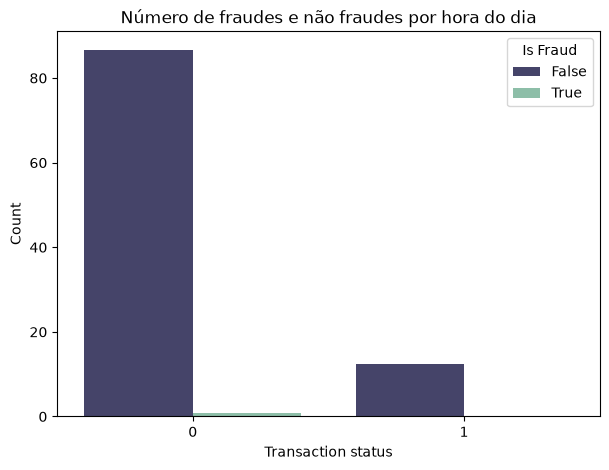

In [19]:
plt.figure(figsize=(7, 5))
sns.countplot(x='dawn', data=dfCopy, palette = ['#3f3e6fd1', '#85c6a9'],hue='is_fraud',stat='percent')
plt.title('Número de fraudes e não fraudes por hora do dia')
plt.xlabel("Transaction status")
plt.ylabel("Count")
plt.legend(title="Is Fraud")
plt.show()

C:\Users\lf446\AppData\Local\Temp\ipykernel_18964\759343772.py:3: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.countplot(x='hour', data=onlyFraudes, palette = ['#3f3e6fd1', '#85c6a9'],hue='is_fraud',stat='percent')


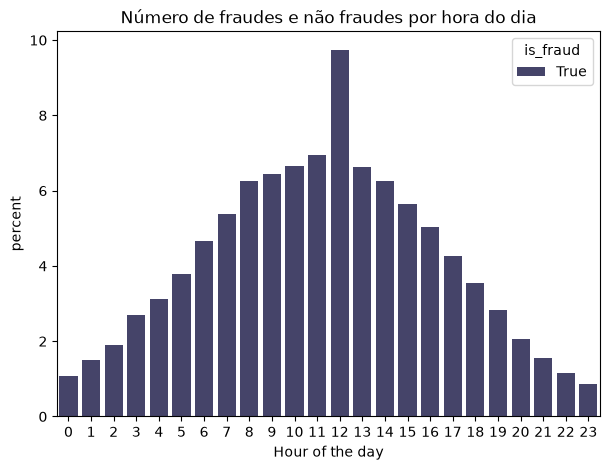

In [20]:
onlyFraudes = dfCopy.loc[lambda x: x["is_fraud"]==True]
plt.figure(figsize=(7, 5))
sns.countplot(x='hour', data=onlyFraudes, palette = ['#3f3e6fd1', '#85c6a9'],hue='is_fraud',stat='percent')
plt.title('Número de fraudes e não fraudes por hora do dia')
plt.xlabel("Hour of the day")
plt.ylabel("percent")
plt.show()

## Desvio padrão e Z-score
Lembrando que o desvio padrão deve conter apenas transações antes dela e caso alguma fraude tenha ocorrido e não tenha sido detectada, o desvio padrão deve ser calculado junto com essa fraude(caso real)
---
Z-score é uma medida estatística que indica quantos desvios padrão um determinado valor está distante da média de um conjunto de dados. Ele é calculado usando a fórmula:
Z = (X - μ) / σ
onde:
- X é o valor que você deseja padronizar,
- μ é a média do conjunto de dados,
- σ é o desvio padrão do conjunto de dados.
ele serve para identificar valores atípicos (outliers) em um conjunto de dados. Valores de Z-score acima de 3 ou abaixo de -3 são geralmente considerados outliers.

In [21]:
"""
def estatisticas_temporais(transacoes):
    dados = transacoes.copy()
    dados["tx_datetime"] = pd.to_datetime(dados["tx_datetime"], errors="raise")
    dados["tx_fraud_report_date"] = pd.to_datetime(
        dados["tx_fraud_report_date"], errors="raise"
    )
    dados["tx_amount"] = pd.to_numeric(dados["tx_amount"], errors="raise").astype(float)

    dados = dados.drop(
        columns=["history_count", "mean_amount", "std_amount", "z_score"],
        errors="ignore",
    )
    dados["_linha"] = range(len(dados))

    def relacionar_historico(cartao):
        consultas = cartao[["_linha", "tx_datetime"]]
        historico = cartao[["tx_datetime", "tx_amount", "tx_fraud_report_date"]]
        pares = consultas.merge(
            historico, how="cross", suffixes=("_analise", "_historico")
        )

        elegiveis = pares.loc[
            (pares["tx_datetime_historico"] < pares["tx_datetime_analise"])
            & (
                pares["tx_fraud_report_date"].isna()
                | (pares["tx_fraud_report_date"] > pares["tx_datetime_analise"])
            )
        ]
        return (
            elegiveis.groupby("_linha")["tx_amount"]
            .agg(history_count="count", mean_amount="mean", std_amount="std")
            .reset_index()
        )

    if dados.empty:
        return dados.drop(columns="_linha").assign(
            history_count=pd.Series(dtype="int64"),
            mean_amount=float("nan"),
            std_amount=float("nan"),
            z_score=float("nan"),
        )

    estatisticas = (
        dados.groupby("card_id", group_keys=False)[
            ["_linha", "tx_datetime", "tx_amount", "tx_fraud_report_date"]
        ]
        .apply(relacionar_historico)
    )

    resultado = (
        dados.merge(
            estatisticas,
            on="_linha",
            how="left",
            validate="one_to_one",
            sort=False,
        )
        .sort_values("_linha")
    )
    resultado["history_count"] = (
        resultado["history_count"].fillna(0).astype("int64")
    )
    resultado["z_score"] = (
        (resultado["tx_amount"] - resultado["mean_amount"])
        / resultado["std_amount"].where(resultado["std_amount"].gt(0))
    )

    resultado = resultado.drop(columns="_linha")
    resultado.index = transacoes.index
    return resultado


dfDesvioPadrao = estatisticas_temporais(dfTransactions)
semNan = dfDesvioPadrao["std_amount"].dropna()
semNan  """

559         53.754261
715         42.383982
781        213.539170
882          5.366941
937         62.925428
              ...    
4483951    120.288393
4483952     21.186897
4483953    203.026960
4483954     44.936913
4483955     65.073828
Name: std_amount, Length: 4464331, dtype: float64

In [22]:
"""dfTransactions"""

'dfTransactions'

## Numero de compras nas ultimas 1,6,12,24 horas

In [23]:
numHoras = [1, 6, 12, 24]
graficos = []

base = dfTransactions.copy()
base["dateTime"] = pd.to_datetime(base["tx_datetime"])

# Rolling temporal exige dados ordenados
base = base.sort_values(["card_id", "dateTime"])

for horas in numHoras:
    dfCopy = base.copy()

    dfCopy["count_transactions"] = (
        dfCopy.groupby("card_id")["dateTime"]
        .transform(
            lambda datas: (
                pd.Series(1, index=datas)
                .rolling(f"{horas}h")
                .sum()
                .to_numpy()
            )
        )
        .astype(int)
    )

    graficos.append(dfCopy)

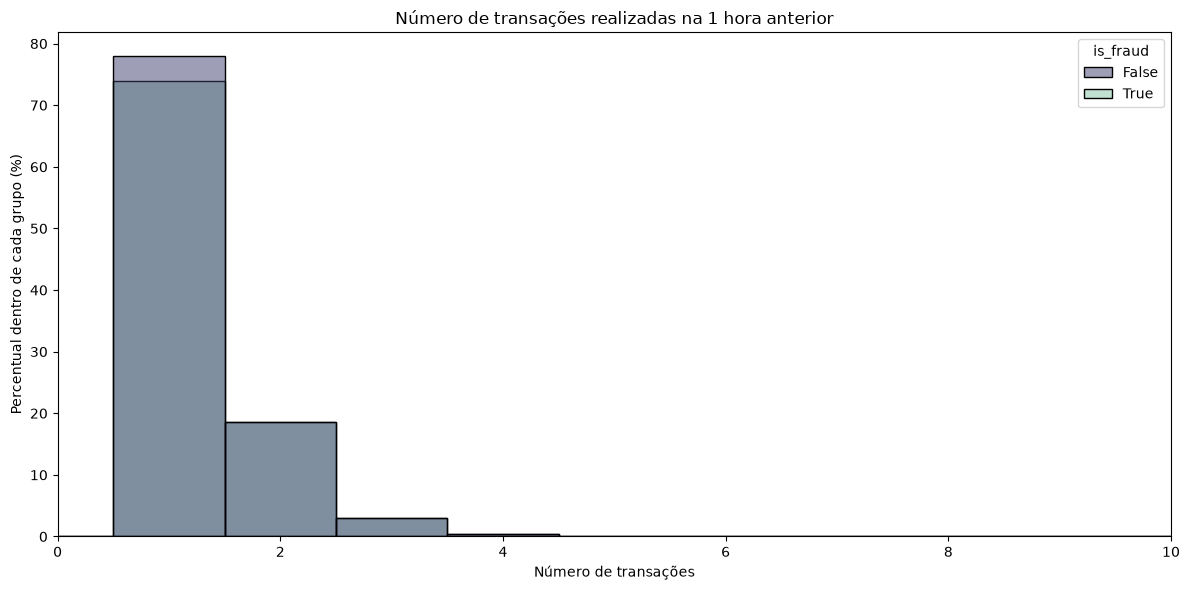

In [24]:
plt.figure(figsize=(12, 6))

hora = 1
filtrado = graficos[0]
#filtrado = filtrado.loc[filtrado["is_fraud"] == True]

sns.histplot(
    data=filtrado,
    x="count_transactions",
    hue="is_fraud",
    bins=40,
    binrange=(0, 40),
    stat="percent",
    common_norm=False,
    kde=False,
    discrete=True,
    palette=["#3f3e6f", "#85c6a9"]
)

plt.title(f"Número de transações realizadas na {hora} hora anterior")
plt.xlabel("Número de transações")
plt.xlim(0,10)
plt.ylabel("Percentual dentro de cada grupo (%)")
plt.tight_layout()
plt.show()

## Z-Score

In [25]:
dadosPerdidos = dfDesvioPadrao["std_amount"].isna()


total_sem_desvio = dadosPerdidos.sum()

fraudes_sem_desvio = (
    dadosPerdidos
    & dfDesvioPadrao["is_fraud"].eq(True)
).sum()

print(f"Dados totais sem desvio padrão: {total_sem_desvio}")
print(f"Fraudes sem desvio padrão: {fraudes_sem_desvio}")

Dados totais sem desvio padrão: 19625
Fraudes sem desvio padrão: 119


In [26]:

Zscore = dfDesvioPadrao.copy()
Zscore


,transaction_id,tx_datetime,tx_date,tx_time,tx_amount,card_id,terminal_id,is_transactional_fraud,is_fraud,tx_fraud_report_date,history_count,mean_amount,std_amount,z_score
0,1,2018-01-01 00:00:10,2018-01-01,00:00:10,117.120003,4983922282101,1113,0,False,NaT,0,NaN,NaN,NaN
1,2,2018-01-01 00:00:38,2018-01-01,00:00:38,57.700001,38435765939628,790,0,False,NaT,0,NaN,NaN,NaN
2,3,2018-01-01 00:00:38,2018-01-01,00:00:38,41.500000,4053973451359964262,157,0,False,NaT,0,NaN,NaN,NaN
3,4,2018-01-01 00:00:41,2018-01-01,00:00:41,47.720001,370458387500772,850,0,False,NaT,0,NaN,NaN,NaN
4,5,2018-01-01 00:01:46,2018-01-01,00:01:46,14.530000,180022431672084,32,0,False,NaT,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4483951,4483952,2018-05-31 23:58:55,2018-05-31,23:58:55,61.299999,6011387595594222,429,0,False,NaT,979,95.106364,120.288393,-0.281044
4483952,4483953,2018-05-31 23:58:59,2018-05-31,23:58:59,5.510000,30354053340167,1760,0,False,NaT,684,19.395673,21.186897,-0.655390
4483953,4483954,2018-05-31 23:59:18,2018-05-31,23:59:18,59.549999,4472226472833343268,937,0,False,NaT,464,122.200948,203.026960,-0.308584
4483954,4483955,2018-05-31 23:59:24,2018-05-31,23:59:24,53.150002,4627244522757,575,0,False,NaT,995,51.204693,44.936913,0.043290


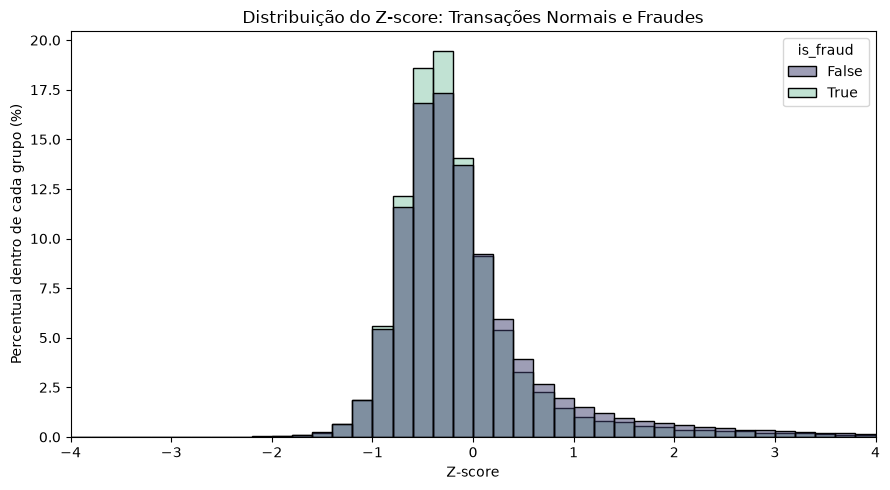

In [27]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=Zscore,
    x="z_score",
    hue="is_fraud",
    bins=40,
    binrange=(-4, 4),
    stat="percent",
    common_norm=False,
    kde=False,
    palette=["#3f3e6f", "#85c6a9"],
    alpha=0.5
)

plt.xlim(-4, 4)
plt.xticks(range(-4, 5))
plt.title("Distribuição do Z-score: Transações Normais e Fraudes")
plt.xlabel("Z-score")
plt.ylabel("Percentual dentro de cada grupo (%)")
plt.tight_layout()
plt.show()

C:\Users\lf446\AppData\Local\Temp\ipykernel_18964\4280306398.py:4: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.histplot(


Text(0, 0.5, 'Percentual dentro de cada grupo (%)')

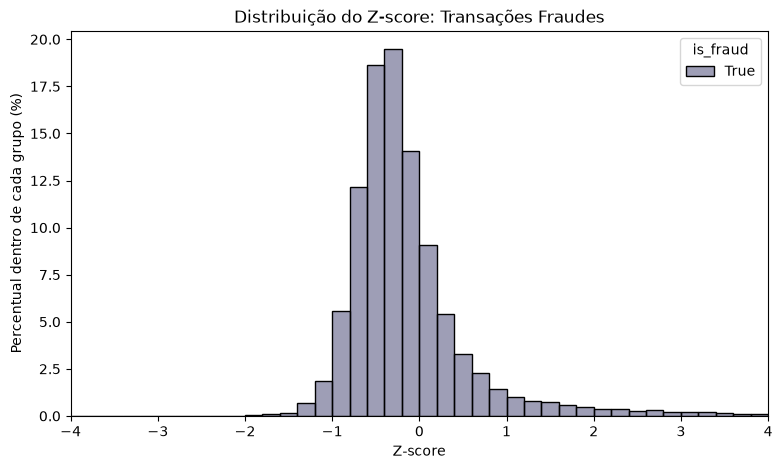

In [28]:
onlyFraudes = Zscore.loc[lambda x: x["is_fraud"]==True]
plt.figure(figsize=(9, 5))

sns.histplot(
    data=onlyFraudes,
    x="z_score",
    hue="is_fraud",
    bins=40,
    binrange=(-4, 4),
    stat="percent",
    common_norm=False,
    kde=False,
    palette=["#3f3e6f", "#85c6a9"],
    alpha=0.5
)

plt.xlim(-4, 4)
plt.xticks(range(-4, 5))
plt.title("Distribuição do Z-score: Transações Fraudes")
plt.xlabel("Z-score")
plt.ylabel("Percentual dentro de cada grupo (%)")

# Hipoteses

## 1° Hipostese: Terminais antigos provem mais transações falsas



## Geração de um dataframe com o tempo de vida do terminal juntamente com a transação

In [29]:
dfTerminalTransacao = dfTransactions.merge(
    dfSellers,
    on="terminal_id",
    how="left",
    validate="many_to_one"
)


dfTerminalTransacao["tx_datetime"] = pd.to_datetime(
    dfTerminalTransacao["tx_datetime"], errors="coerce"
)
dfTerminalTransacao["terminal_operation_start"] = pd.to_datetime(
    dfTerminalTransacao["terminal_operation_start"], errors="coerce"
)
dfTerminalTransacao["terminal_age_days"] = (
    dfTerminalTransacao["tx_datetime"]
    - dfTerminalTransacao["terminal_operation_start"]
).dt.days


dfTerminalTransacao.head()

,transaction_id,tx_datetime,tx_date,tx_time,tx_amount,card_id,terminal_id,is_transactional_fraud,is_fraud,tx_fraud_report_date,latitude,longitude,terminal_operation_start,terminal_soft_descriptor,terminal_age_days
0,1,2018-01-01 00:00:10,2018-01-01,00:00:10,117.120003,4983922282101,1113,0,False,NaT,-15.705911,-47.873059,2017-11-12,Ifood BBQ Hub 65,50
1,2,2018-01-01 00:00:38,2018-01-01,00:00:38,57.700001,38435765939628,790,0,False,NaT,-3.027345,-59.991758,2017-08-06,Modern Sofa Store 92,148
2,3,2018-01-01 00:00:38,2018-01-01,00:00:38,41.500000,4053973451359964262,157,0,False,NaT,-23.579366,-46.560141,2017-01-09,Elite Hair Salon 78,357
3,4,2018-01-01 00:00:41,2018-01-01,00:00:41,47.720001,370458387500772,850,0,False,NaT,-23.548920,-46.613343,2017-08-27,Cyber World 128,127
4,5,2018-01-01 00:01:46,2018-01-01,00:01:46,14.530000,180022431672084,32,0,False,NaT,-15.792368,-47.884698,2016-08-29,Live Music Hub 41,490


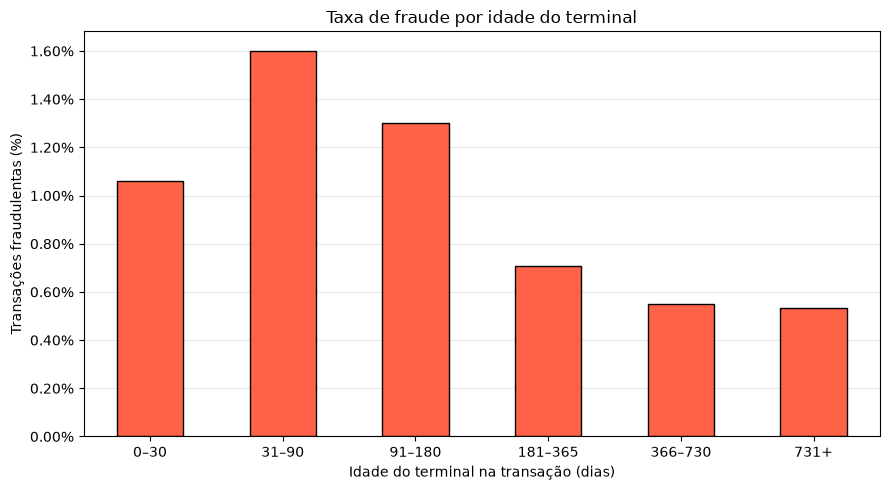

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

dados = dfTerminalTransacao.dropna(
    subset=["terminal_age_days", "is_fraud"]
).copy()

dados = dados.loc[dados["terminal_age_days"] >= 0]

dados["faixa_idade"] = pd.cut(
    dados["terminal_age_days"],
    bins=[0, 30, 90, 180, 365, 730, float("inf")],
    labels=["0–30", "31–90", "91–180", "181–365", "366–730", "731+"],
    include_lowest=True
)

taxa_fraude = (
    dados.groupby("faixa_idade", observed=True)["is_fraud"]
    .mean()
    .mul(100)
)

ax = taxa_fraude.plot.bar(
    figsize=(9, 5),
    color="tomato",
    edgecolor="black",
    rot=0
)

ax.set_title("Taxa de fraude por idade do terminal")
ax.set_xlabel("Idade do terminal na transação (dias)")
ax.set_ylabel("Transações fraudulentas (%)")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


## 2°Hipotese: As fraudes estão relacionadas com um dia especifíco da semana

In [31]:
#Retorna um valor entre 0-6 sendo 0 domingo, 1 segunda ... 6 sabado
def transformarDataEmDiaSemana(txDate):
    return (txDate.weekday() + 1) % 7


dfDiaSemana = dfTransactions
dfDiaSemana["day_week"] = dfTransactions["tx_date"].apply(transformarDataEmDiaSemana)
dfDiaSemana


,transaction_id,tx_datetime,tx_date,tx_time,tx_amount,card_id,terminal_id,is_transactional_fraud,is_fraud,tx_fraud_report_date,day_week
0,1,2018-01-01 00:00:10,2018-01-01,00:00:10,117.120003,4983922282101,1113,0,False,NaT,1
1,2,2018-01-01 00:00:38,2018-01-01,00:00:38,57.700001,38435765939628,790,0,False,NaT,1
2,3,2018-01-01 00:00:38,2018-01-01,00:00:38,41.500000,4053973451359964262,157,0,False,NaT,1
3,4,2018-01-01 00:00:41,2018-01-01,00:00:41,47.720001,370458387500772,850,0,False,NaT,1
4,5,2018-01-01 00:01:46,2018-01-01,00:01:46,14.530000,180022431672084,32,0,False,NaT,1
...,...,...,...,...,...,...,...,...,...,...,...
4483951,4483952,2018-05-31 23:58:55,2018-05-31,23:58:55,61.299999,6011387595594222,429,0,False,NaT,4
4483952,4483953,2018-05-31 23:58:59,2018-05-31,23:58:59,5.510000,30354053340167,1760,0,False,NaT,4
4483953,4483954,2018-05-31 23:59:18,2018-05-31,23:59:18,59.549999,4472226472833343268,937,0,False,NaT,4
4483954,4483955,2018-05-31 23:59:24,2018-05-31,23:59:24,53.150002,4627244522757,575,0,False,NaT,4


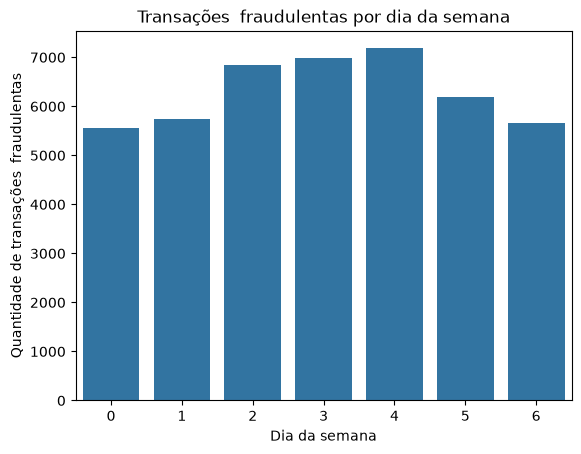

In [32]:
sns.countplot(
    data=dfDiaSemana.loc[
        (dfDiaSemana["is_fraud"] == True)
    ],
    x="day_week",
    order=range(7)
)

plt.xlabel("Dia da semana")
plt.ylabel("Quantidade de transações  fraudulentas")
plt.title("Transações  fraudulentas por dia da semana")
plt.show()

## Hiptose 3: Fraudes tem um desvio significativo da media das transações feitas antes

In [33]:
dfTransactions.head()

,transaction_id,tx_datetime,tx_date,tx_time,tx_amount,card_id,terminal_id,is_transactional_fraud,is_fraud,tx_fraud_report_date,day_week
0,1,2018-01-01 00:00:10,2018-01-01,00:00:10,117.120003,4983922282101,1113,0,False,NaT,1
1,2,2018-01-01 00:00:38,2018-01-01,00:00:38,57.700001,38435765939628,790,0,False,NaT,1
2,3,2018-01-01 00:00:38,2018-01-01,00:00:38,41.500000,4053973451359964262,157,0,False,NaT,1
3,4,2018-01-01 00:00:41,2018-01-01,00:00:41,47.720001,370458387500772,850,0,False,NaT,1
4,5,2018-01-01 00:01:46,2018-01-01,00:01:46,14.530000,180022431672084,32,0,False,NaT,1


In [34]:
# Reutiliza estatisticas calculadas com o conhecimento no instante da analise.
# O rotulo final is_fraud serve apenas para avaliacao e visualizacao.
dfStd = dfDesvioPadrao.copy()


In [35]:

dfStd.loc[dfStd["std_amount"].notnull() & dfStd["is_fraud"]==True, ["card_id", "tx_datetime", "tx_amount", "std_amount"]]

,card_id,tx_datetime,tx_amount,std_amount
3065,30114773201010,2018-01-01 06:09:10,40.490002,12.402542
4571,3577376606259373,2018-01-01 07:29:57,83.279999,96.598661
5314,341805105119317,2018-01-01 08:04:12,17.129999,0.395979
5688,6576296029649915,2018-01-01 08:21:05,63.740002,11.219949
6712,371638883289975,2018-01-01 09:06:27,148.850006,49.925641
...,...,...,...,...
4483688,6511810220317318,2018-05-31 23:03:28,323.220001,72.267423
4483757,3590608276100237,2018-05-31 23:16:33,116.650002,74.301016
4483781,38718316407447,2018-05-31 23:20:16,5.270000,14.007472
4483836,4420522589873071,2018-05-31 23:30:56,15.330000,9.440527


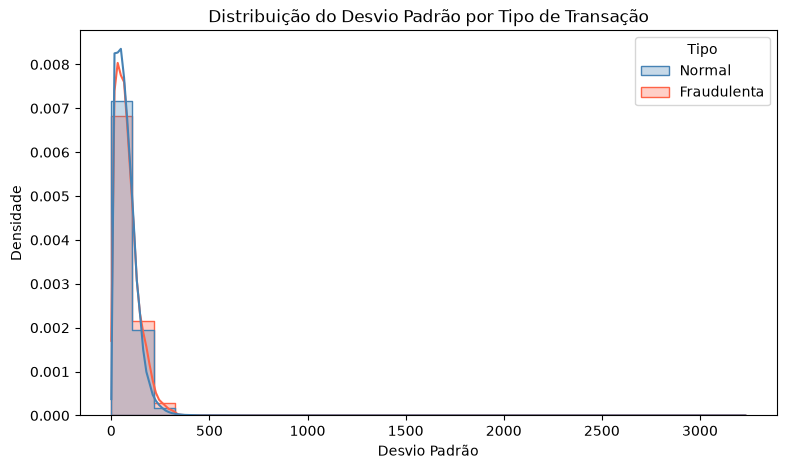

In [36]:
dfStdCopy = dfStd.dropna(subset=["std_amount"]).copy()

dfStdCopy["Tipo"] = dfStdCopy["is_fraud"].map({
    False: "Normal",
    True: "Fraudulenta"
})

plt.figure(figsize=(9, 5))

sns.histplot(
    data=dfStdCopy,
    x="std_amount",
    hue="Tipo",
    hue_order=["Normal", "Fraudulenta"],
    bins=30,
    kde=True,
    stat="density",
    common_norm=False,
    element="step",
    alpha=0.3,
    palette={"Normal": "steelblue", "Fraudulenta": "tomato"}
)

plt.title("Distribuição do Desvio Padrão por Tipo de Transação")
plt.ylabel("Densidade")
plt.xlabel("Desvio Padrão")

plt.show()

## Hipotse 4: Calculo do z-score
Z-score é uma medida estatística que indica quantos desvios padrão um determinado valor está distante da média de um conjunto de dados. Ele é calculado usando a fórmula:
Z = (X - μ) / σ
onde:
- X é o valor que você deseja padronizar,
- μ é a média do conjunto de dados,
- σ é o desvio padrão do conjunto de dados.
ele serve para identificar valores atípicos (outliers) em um conjunto de dados. Valores de Z-score acima de 3 ou abaixo de -3 são geralmente considerados outliers.

fontes:
- https://maisretorno.com/portal/termos/z/z-score
- https://www.datacamp.com/pt/tutorial/z-score

In [37]:
# Usa o mesmo z-score temporal, sem recalcular estatisticas globais.
dfZScore = dfStd.copy()
dfZScore.loc[
    dfZScore["z_score"].notna() & dfZScore["is_fraud"].eq(True),
    ["card_id", "tx_datetime", "tx_amount", "z_score"],
]


,card_id,tx_datetime,tx_amount,z_score
3065,30114773201010,2018-01-01 06:09:10,40.490002,0.005913
4571,3577376606259373,2018-01-01 07:29:57,83.279999,-0.102589
5314,341805105119317,2018-01-01 08:04:12,17.129999,-3.080969
5688,6576296029649915,2018-01-01 08:21:05,63.740002,3.119147
6712,371638883289975,2018-01-01 09:06:27,148.850006,0.767608
...,...,...,...,...
4483688,6511810220317318,2018-05-31 23:03:28,323.220001,3.674256
4483757,3590608276100237,2018-05-31 23:16:33,116.650002,0.269847
4483781,38718316407447,2018-05-31 23:20:16,5.270000,-0.672124
4483836,4420522589873071,2018-05-31 23:30:56,15.330000,0.179179


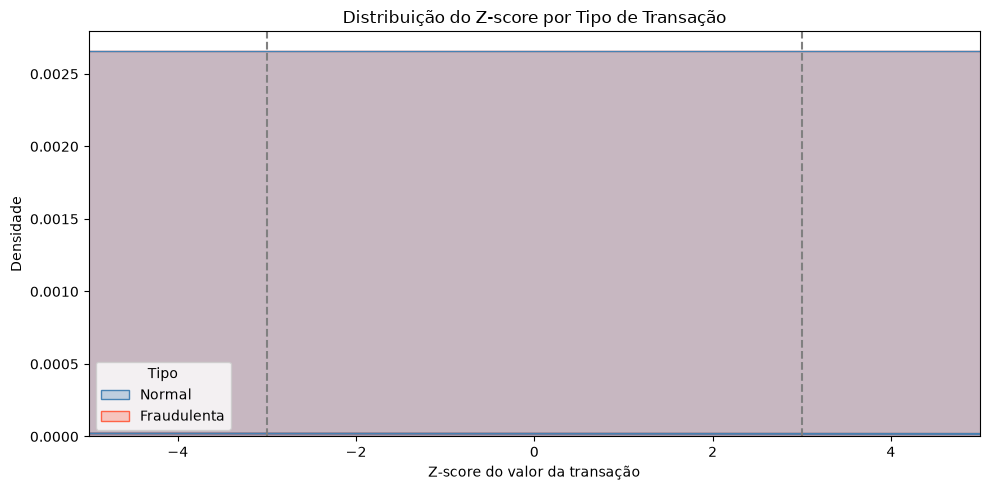

In [38]:
dfPlot = dfZScore.dropna(subset=["z_score", "is_fraud"]).copy()
dfPlot["Tipo"] = dfPlot["is_fraud"].map({
    False: "Normal",
    True: "Fraudulenta"
})

plt.figure(figsize=(10, 5))

sns.histplot(
    data=dfPlot,
    x="z_score",
    hue="Tipo",
    hue_order=["Normal", "Fraudulenta"],
    bins=40,
    kde=True,
    stat="density",
    common_norm=False,
    element="step",
    alpha=0.3,
    palette={"Normal": "steelblue", "Fraudulenta": "tomato"}
)

plt.axvline(-3, color="gray", linestyle="--")
plt.axvline(3, color="gray", linestyle="--")
plt.xlim(-5, 5)
plt.title("Distribuição do Z-score por Tipo de Transação")
plt.xlabel("Z-score do valor da transação")
plt.ylabel("Densidade")
plt.tight_layout()
plt.show()

## Hipótese 5: as fraudes acontecem em terminais diferentes dos das transações normais?

In [39]:
dfRel = dfTransactions.merge(
    dfSellers[["terminal_id", "latitude", "longitude"]],
    on="terminal_id", how="left", validate="many_to_one"
)
dfRel["tx_datetime"] = pd.to_datetime(dfRel["tx_datetime"])
dfRel = dfRel.sort_values(["card_id", "tx_datetime"]).reset_index(drop=True)
dfRel["is_fraud"] = dfRel["is_fraud"].astype(bool)
dfRel.shape

(4483956, 13)

#### fraudes se concentram em poucos terminais?

Terminais com pelo menos 1 fraude: 99.6%
Taxa de fraude global: 0.99%


,n_tx,n_fraude,taxa
terminal_id,,,
1192,3427,3142,0.916837
1133,2380,2380,1.000000
1170,2518,2087,0.828832
666,4729,2016,0.426306
1289,2239,1759,0.785619
1387,2446,1658,0.677841
1445,1599,1576,0.985616
1649,1949,1455,0.746537
1949,1138,1123,0.986819


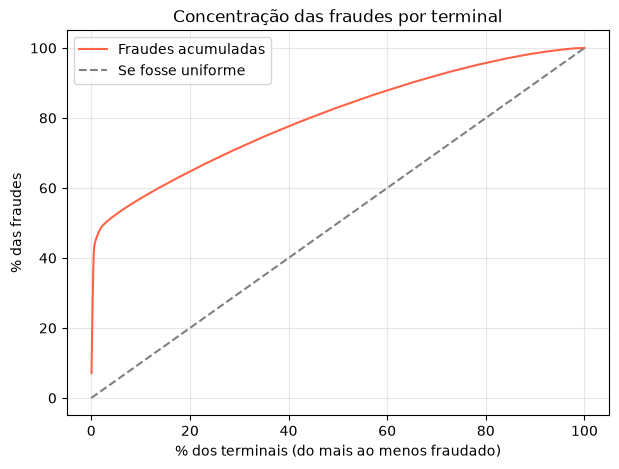

In [40]:
por_terminal = dfRel.groupby("terminal_id")["is_fraud"].agg(n_tx="size", n_fraude="sum")
por_terminal["taxa"] = por_terminal["n_fraude"] / por_terminal["n_tx"]

print(f"Terminais com pelo menos 1 fraude: {(por_terminal['n_fraude'] > 0).mean():.1%}")
print(f"Taxa de fraude global: {dfRel['is_fraud'].mean():.2%}")
display(por_terminal.sort_values("n_fraude", ascending=False).head(10))

ordenado = por_terminal.sort_values("n_fraude", ascending=False)
acum = ordenado["n_fraude"].cumsum() / ordenado["n_fraude"].sum()
x = np.arange(1, len(ordenado) + 1) / len(ordenado)

plt.figure(figsize=(7, 5))
plt.plot(x * 100, acum.values * 100, label="Fraudes acumuladas", color="tomato")
plt.plot([0, 100], [0, 100], "--", color="gray", label="Se fosse uniforme")
plt.xlabel("% dos terminais (do mais ao menos fraudado)")
plt.ylabel("% das fraudes")
plt.title("Concentração das fraudes por terminal")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### o cartão está usando um terminal novo?

C:\Users\lf446\AppData\Local\Temp\ipykernel_18964\1420656356.py:8: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  dfRel["terminais_novos_7d"] = tmp.groupby("card_id")["terminal_novo"].rolling("7d").sum().to_numpy()


terminal_novo
terminal já usado    1.057029
terminal novo        0.926908
Name: is_fraud, dtype: float64


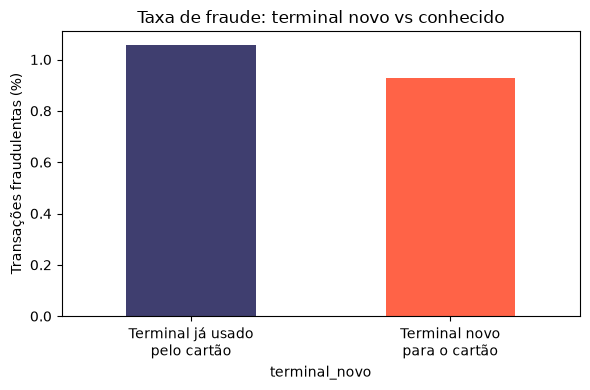

In [41]:
primeira_vez_par = ~dfRel.duplicated(["card_id", "terminal_id"])
primeira_tx_cartao = dfRel.groupby("card_id").cumcount() == 0

dfRel["terminal_novo"] = (primeira_vez_par & ~primeira_tx_cartao).astype(int)
dfRel["n_terminais_hist"] = primeira_vez_par.astype(int).groupby(dfRel["card_id"]).cumsum()

tmp = dfRel.set_index("tx_datetime")
dfRel["terminais_novos_7d"] = tmp.groupby("card_id")["terminal_novo"].rolling("7d").sum().to_numpy()

taxa = dfRel.groupby("terminal_novo")["is_fraud"].mean().mul(100)
print(taxa.rename({0: "terminal já usado", 1: "terminal novo"}))

ax = taxa.rename({0: "Terminal já usado\npelo cartão", 1: "Terminal novo\npara o cartão"}).plot.bar(
    color=["#3f3e6f", "tomato"], rot=0, figsize=(6, 4))
ax.set_ylabel("Transações fraudulentas (%)")
ax.set_title("Taxa de fraude: terminal novo vs conhecido")
plt.tight_layout()
plt.show()

#### existe um grupo de terminais suspeitos?

In [42]:
taxa_global = dfRel["is_fraud"].mean()
suspeitos = por_terminal.index[(por_terminal["taxa"] > 5 * taxa_global) & (por_terminal["n_tx"] >= 30)]

e_suspeito = dfRel["terminal_id"].isin(suspeitos)
print(f"Terminais suspeitos: {len(suspeitos)} de {len(por_terminal)} ({len(suspeitos)/len(por_terminal):.1%})")
print(f"Fraudes que caem em terminais suspeitos: {e_suspeito[dfRel['is_fraud']].mean():.1%}")
print(f"Transações normais em terminais suspeitos: {e_suspeito[~dfRel['is_fraud']].mean():.1%}")

Terminais suspeitos: 17 de 2000 (0.9%)
Fraudes que caem em terminais suspeitos: 44.7%
Transações normais em terminais suspeitos: 0.3%


## Hipotese 6: Fraudes por categoria de terminal

In [43]:
categorias = dfSellers.copy()

categorias["terminal_category"] = (
    categorias["terminal_soft_descriptor"]
    .str.replace(r"\s+\d+$", "", regex=True)
    .str.strip()
)

dfTransactionsCategoria = dfTransactions.merge(
    categorias[["terminal_id", "terminal_category"]],
    on="terminal_id",
    how="left",
    validate="many_to_one"
)




dfTransactionsCategoria


,transaction_id,tx_datetime,tx_date,tx_time,tx_amount,card_id,terminal_id,is_transactional_fraud,is_fraud,tx_fraud_report_date,day_week,terminal_category
0,1,2018-01-01 00:00:10,2018-01-01,00:00:10,117.120003,4983922282101,1113,0,False,NaT,1,Ifood BBQ Hub
1,2,2018-01-01 00:00:38,2018-01-01,00:00:38,57.700001,38435765939628,790,0,False,NaT,1,Modern Sofa Store
2,3,2018-01-01 00:00:38,2018-01-01,00:00:38,41.500000,4053973451359964262,157,0,False,NaT,1,Elite Hair Salon
3,4,2018-01-01 00:00:41,2018-01-01,00:00:41,47.720001,370458387500772,850,0,False,NaT,1,Cyber World
4,5,2018-01-01 00:01:46,2018-01-01,00:01:46,14.530000,180022431672084,32,0,False,NaT,1,Live Music Hub
...,...,...,...,...,...,...,...,...,...,...,...,...
4483951,4483952,2018-05-31 23:58:55,2018-05-31,23:58:55,61.299999,6011387595594222,429,0,False,NaT,4,Casual Wear Store
4483952,4483953,2018-05-31 23:58:59,2018-05-31,23:58:59,5.510000,30354053340167,1760,0,False,NaT,4,Taxi Julia
4483953,4483954,2018-05-31 23:59:18,2018-05-31,23:59:18,59.549999,4472226472833343268,937,0,False,NaT,4,Modern Sofa Store
4483954,4483955,2018-05-31 23:59:24,2018-05-31,23:59:24,53.150002,4627244522757,575,0,False,NaT,4,Rappi Savory Delights


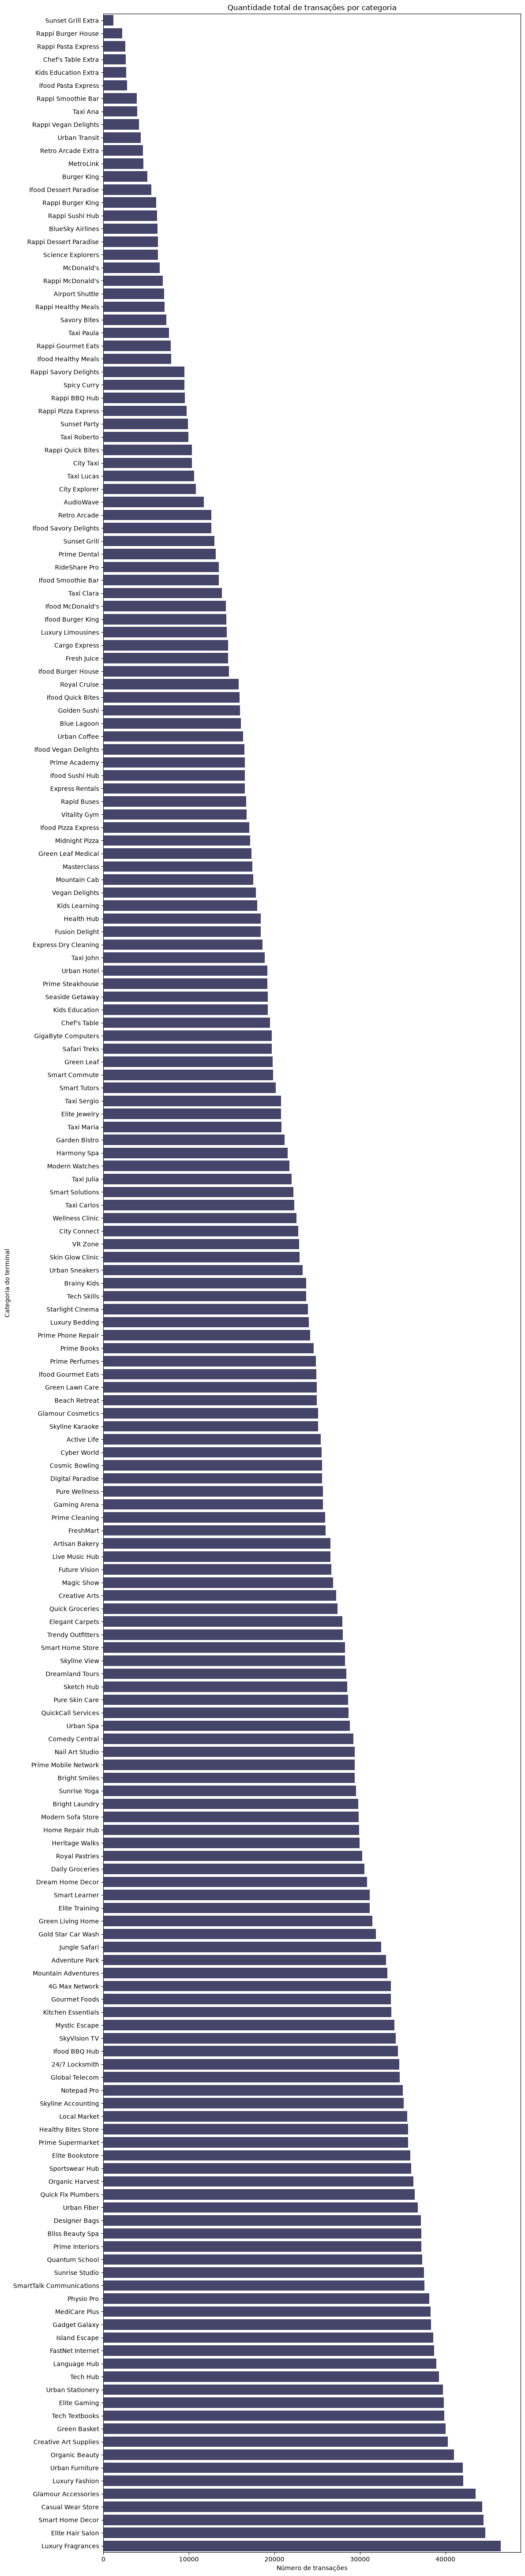

In [44]:
transacoes_por_categoria = (
    dfTransactionsCategoria.copy()
    .groupby("terminal_category")
    .size()
    .reset_index(name="total_transacoes")
    .sort_values("total_transacoes", ascending=True)
)



plt.figure(
    figsize=(12, max(10, len(transacoes_por_categoria) * 0.3))
)

sns.barplot(
    data=transacoes_por_categoria,
    x="total_transacoes",
    y="terminal_category",
    color="#3f3e6f"
)

plt.title("Quantidade total de transações por categoria")
plt.xlabel("Número de transações")
plt.ylabel("Categoria do terminal")
plt.tight_layout()
plt.show()

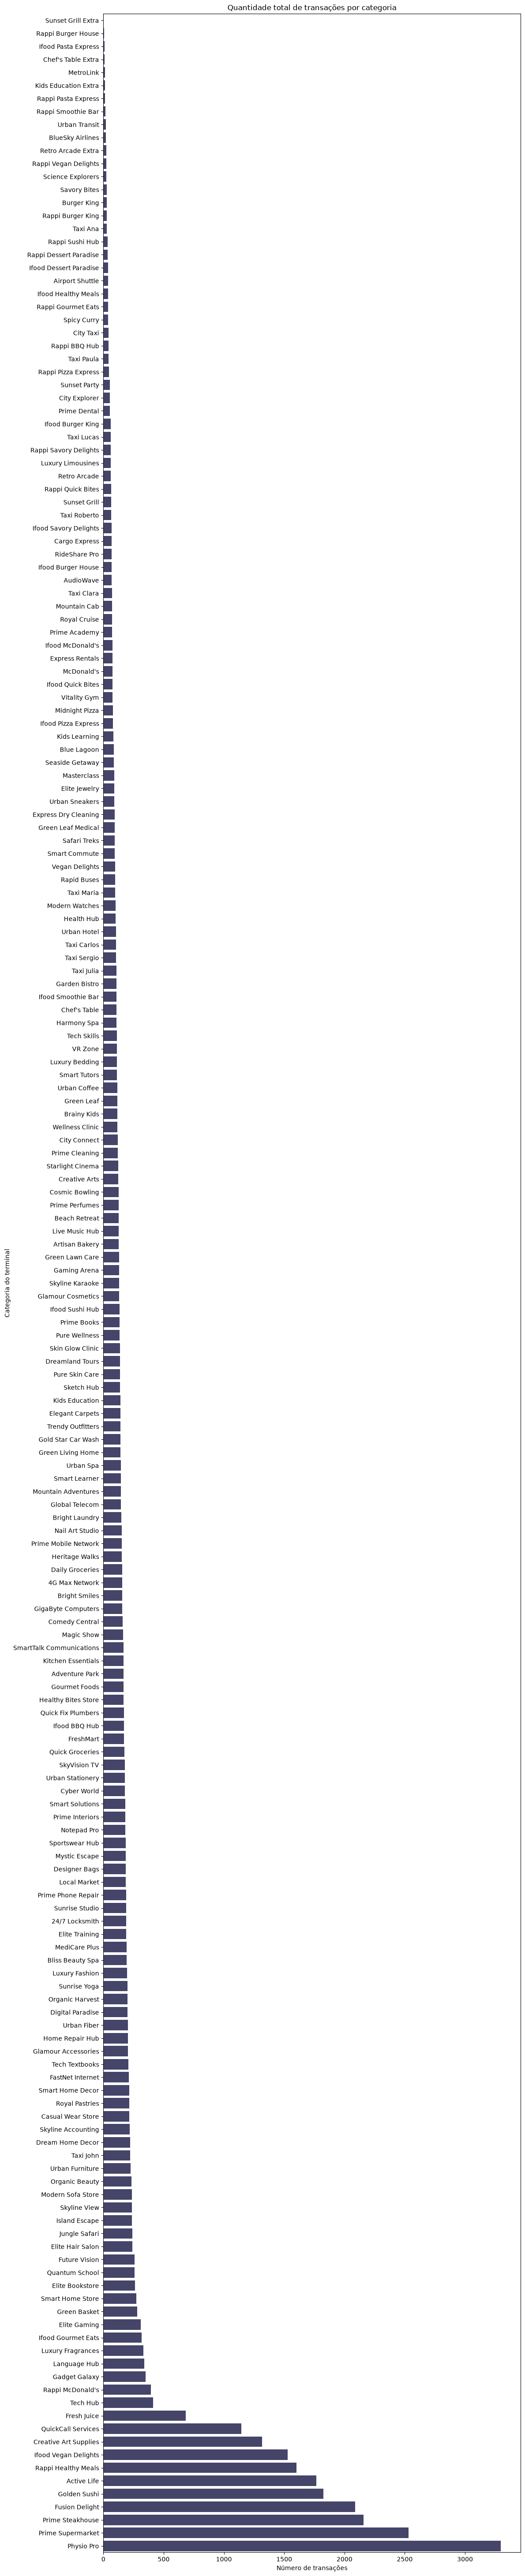

In [45]:
transacoes_por_categoria = (
        dfTransactionsCategoria.copy()
        .loc[lambda x: x["is_fraud"] == True]
        .groupby("terminal_category")
        .size()
        .reset_index(name="total_transacoes")
        .sort_values("total_transacoes", ascending=True)
    )



plt.figure(
        figsize=(12, max(10, len(transacoes_por_categoria) * 0.3))
    )

sns.barplot(
        data=transacoes_por_categoria,
        x="total_transacoes",
        y="terminal_category",
        color="#3f3e6f"
    )

plt.title("Quantidade total de transações por categoria")
plt.xlabel("Número de transações")
plt.ylabel("Categoria do terminal")
plt.tight_layout()
plt.show()

    terminal_category  is_fraud  total_transacoes
0      24/7 Locksmith     False             34435
1      24/7 Locksmith      True               190
2      4G Max Network     False             33449
3      4G Max Network      True               156
4         Active Life     False             23645
..                ...       ...               ...
385    Vegan Delights      True                96
386      Vitality Gym     False             16652
387      Vitality Gym      True                76
388   Wellness Clinic     False             22446
389   Wellness Clinic      True               117

[390 rows x 3 columns]


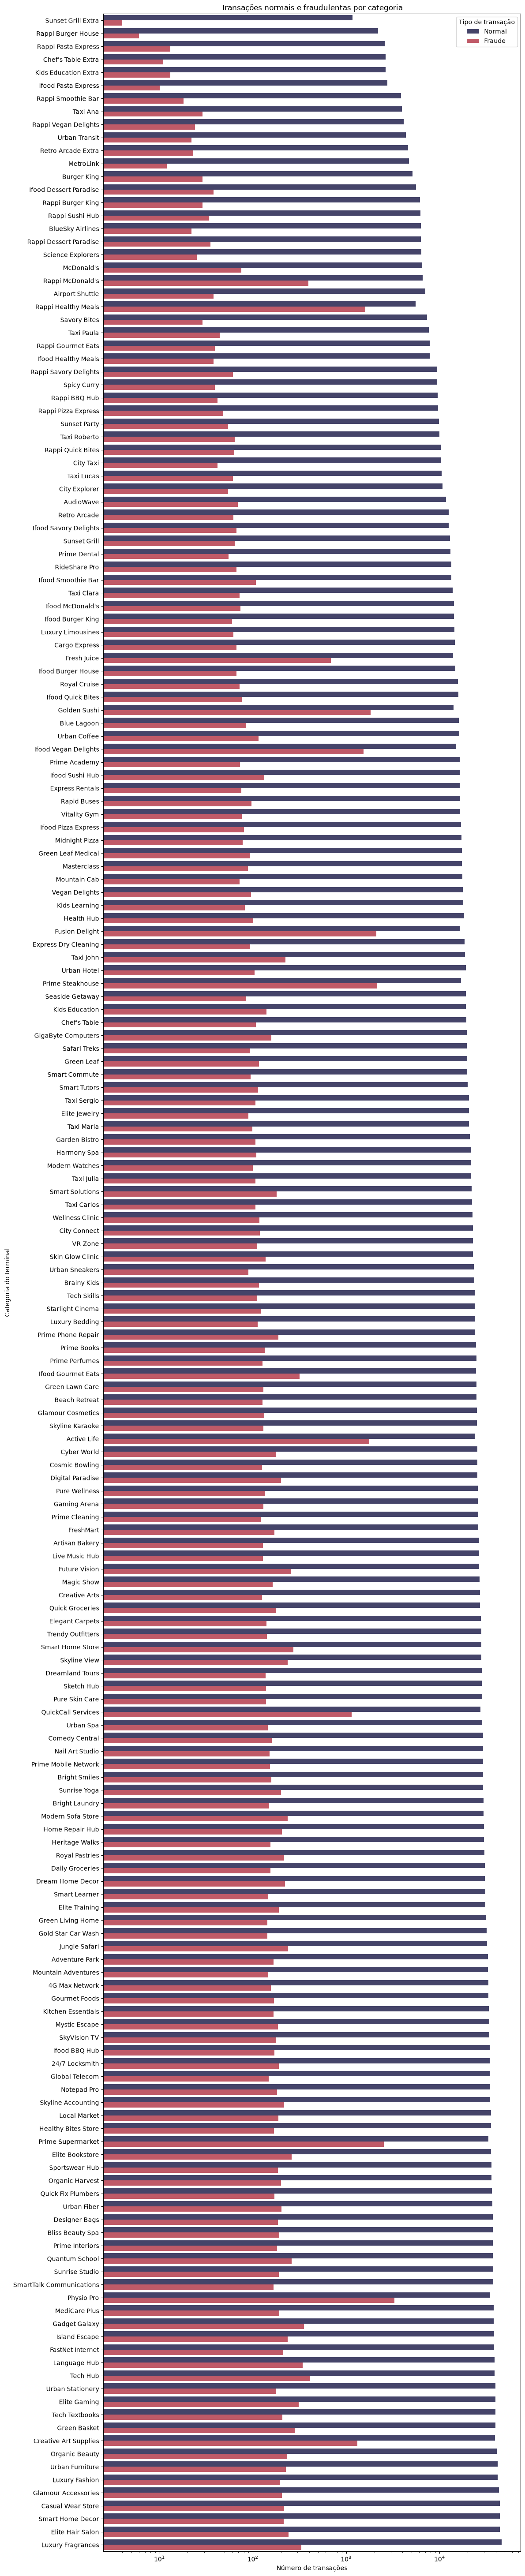

In [46]:
transacoes_por_categoria = (
    dfTransactionsCategoria.copy()
    .groupby(["terminal_category", "is_fraud"])
    .size()
    .reset_index(name="total_transacoes")
)
print(transacoes_por_categoria)
transacoes_por_categoria["tipo_transacao"] = (
    transacoes_por_categoria["is_fraud"]
    .map({
        False: "Normal",
        True: "Fraude"
    })
)

# Ordena as categorias pelo total geral de transações
ordem_categorias = (
    transacoes_por_categoria
    .groupby("terminal_category")["total_transacoes"]
    .sum()
    .sort_values()
    .index
)

plt.figure(
    figsize=(12, max(10, len(ordem_categorias) * 0.3))
)

sns.barplot(
    data=transacoes_por_categoria,
    x="total_transacoes",
    y="terminal_category",
    hue="tipo_transacao",
    hue_order=["Normal", "Fraude"],
    order=ordem_categorias,
    palette={
        "Normal": "#3f3e6f",
        "Fraude": "#d1495b"
    }
)
plt.xscale("log")
plt.title("Transações normais e fraudulentas por categoria")
plt.xlabel("Número de transações")
plt.ylabel("Categoria do terminal")
plt.legend(title="Tipo de transação")
plt.tight_layout()
plt.show()

## Hiptose 7: Fraudes estão relacionadas com a distancia entre terminais em um curto espaço de tempo

In [47]:
dfTerminais = dfSellers.copy()
dfClients = dfPayers.copy()
dfClients

,card_hash,card_bin,card_first_transaction
0,6579071715002803,355137,2016-03-20
1,4814157718073,546566,2016-04-09
2,4717474907925,436231,2016-04-17
3,4747611558497388,358161,2016-05-08
4,4689529748023353,655698,2016-06-03
...,...,...,...
9995,4775662056341110,553685,2018-06-29
9996,213167009741885,471094,2018-06-30
9997,30064013748967,502003,2018-06-30
9998,4459688910961,546566,2018-06-30


## Atributos para cada tipo de Fraude


### 1-Fraude de terminal
Várias fraudes ocorrendo no mesmo terminal. atributo para marcar que aquele terminal tem historico suspeito

## taxa de fraude por terminal

In [48]:
# Calcula a taxa conhecida imediatamente antes de cada transacao.
# Considera apenas transacoes anteriores da entidade e reportes ja conhecidos.
def calcular_taxa_historica(transacoes, coluna_entidade):
    taxas = np.full(len(transacoes), np.nan, dtype=float)
    grupos = transacoes.groupby(
        coluna_entidade, sort=False, dropna=False
    ).indices

    for posicoes in grupos.values():
        grupo = transacoes.iloc[posicoes]
        datas_tx = grupo["tx_datetime"].to_numpy(dtype="datetime64[ns]")
        datas_reportadas = grupo["tx_fraud_report_date"].to_numpy(
            dtype="datetime64[ns]"
        )
        validas = ~np.isnat(datas_tx)
        if not validas.any():
            continue

        # Busca estrita exclui transacoes ocorridas no mesmo instante.
        tempos_tx = datas_tx[validas].astype("int64")
        total_anteriores = np.searchsorted(
            np.sort(tempos_tx), tempos_tx, side="left"
        )

        reportadas = validas & ~np.isnat(datas_reportadas)
        tempos_reportes = np.maximum(
            datas_tx[reportadas].astype("int64"),
            datas_reportadas[reportadas].astype("int64"),
        )
        reportes_conhecidos = np.searchsorted(
            np.sort(tempos_reportes), tempos_tx, side="left"
        )

        taxas[posicoes[validas]] = np.divide(
            reportes_conhecidos,
            total_anteriores,
            out=np.full(len(tempos_tx), np.nan, dtype=float),
            where=total_anteriores > 0,
        )

    return taxas

dfTransacao = dfTransactions.copy()
dfTransacao["tx_datetime"] = pd.to_datetime(
    dfTransacao["tx_datetime"], errors="coerce"
)
dfTransacao["tx_fraud_report_date"] = pd.to_datetime(
    dfTransacao["tx_fraud_report_date"], errors="coerce"
)
dfTransacao["taxa_fraude_terminal"] = calcular_taxa_historica(
    dfTransacao, "terminal_id"
)
dfTransacao.sort_values("taxa_fraude_terminal", ascending=False).head(10)


,transaction_id,tx_datetime,tx_date,tx_time,tx_amount,card_id,terminal_id,is_transactional_fraud,is_fraud,tx_fraud_report_date,day_week,taxa_fraude_terminal
3463079,3463080,2018-05-02 02:48:33,2018-05-02,02:48:33,34.660000,4985524140602939,1133,0,True,2018-05-07,3,0.960519
3464803,3464804,2018-05-02 04:52:12,2018-05-02,04:52:12,55.189999,6011595285994755,1133,0,True,2018-05-09,3,0.960000
3469077,3469078,2018-05-02 07:52:02,2018-05-02,07:52:02,15.620000,374568442633339,1133,0,True,2018-05-08,3,0.959481
3470265,3470266,2018-05-02 08:29:09,2018-05-02,08:29:09,27.650000,3594568150895144,1133,0,True,2018-05-06,3,0.958963
3500065,3500066,2018-05-03 06:35:39,2018-05-03,06:35:39,70.129997,676394485863,1133,0,True,2018-05-10,4,0.958713
3470329,3470330,2018-05-02 08:31:12,2018-05-02,08:31:12,160.570007,342476400068754,1133,0,True,2018-05-07,3,0.958446
3501326,3501327,2018-05-03 07:21:37,2018-05-03,07:21:37,74.040001,30206675490590,1133,0,True,2018-05-08,4,0.958199
3470785,3470786,2018-05-02 08:45:02,2018-05-02,08:45:02,30.690001,3514443874751626,1133,0,True,2018-05-11,3,0.957929
3504918,3504919,2018-05-03 09:14:07,2018-05-03,09:14:07,105.570000,3575399893544929,1133,0,True,2018-05-11,4,0.957686
3898892,3898893,2018-05-15 00:01:18,2018-05-15,00:01:18,4.100000,630477421089,1133,0,True,2018-05-21,2,0.957499


## 2 - Fraude do cartão
Várias fraudes ocorrendo no mesmo cartão. atributo para marcar que aquele cartão tem historico suspeito

In [ ]:
# Ordena as transações e preserva a ordem original para desempatar horários iguais.
dfTransactionsHistoricoCartao = dfTransactions.copy()
dfTransactionsHistoricoCartao["original_order"] = range(len(dfTransactionsHistoricoCartao))
dfTransactionsHistoricoCartao["tx_datetime"] = pd.to_datetime(dfTransactionsHistoricoCartao["tx_datetime"])
dfTransactionsHistoricoCartao["tx_fraud_report_date"] = pd.to_datetime(dfTransactionsHistoricoCartao["tx_fraud_report_date"])
dfTransactionsHistoricoCartao = dfTransactionsHistoricoCartao.sort_values(
    ["card_id", "tx_datetime", "original_order"],
    kind="mergesort",
).reset_index(drop=True)

# Conta transações anteriores e terminais distintos já utilizados.
grupos_cartao = dfTransactionsHistoricoCartao.groupby("card_id", sort=False)
dfTransactionsHistoricoCartao["card_previous_tx_count"] = grupos_cartao.cumcount()
terminal_novo = (
    dfTransactionsHistoricoCartao["terminal_id"].notna()
    & ~dfTransactionsHistoricoCartao.duplicated(["card_id", "terminal_id"])
)
dfTransactionsHistoricoCartao["card_distinct_terminals"] = (
    terminal_novo.groupby(dfTransactionsHistoricoCartao["card_id"]).cumsum()
    - terminal_novo.astype(int)
)

# Conta reportes já conhecidos em cada instante com busca binária por cartão.
dfTransactionsHistoricoCartao["card_previous_known_fraud_count"] = 0
for posicoes in grupos_cartao.indices.values():
    transacoes_cartao = dfTransactionsHistoricoCartao.iloc[posicoes]
    reportes = transacoes_cartao.loc[
        transacoes_cartao["tx_fraud_report_date"].notna()
        & (transacoes_cartao["tx_fraud_report_date"] >= transacoes_cartao["tx_datetime"]),
        "tx_fraud_report_date",
    ].sort_values().to_numpy(dtype="datetime64[ns]")
    tempos_transacao = transacoes_cartao["tx_datetime"].to_numpy(dtype="datetime64[ns]")
    dfTransactionsHistoricoCartao.loc[
        posicoes, "card_previous_known_fraud_count"
    ] = np.searchsorted(reportes, tempos_transacao, side="left")

# Sem histórico, a taxa fica nula; a contagem de terminais começa em zero.
dfTransactionsHistoricoCartao["card_fraud_rate"] = (
    dfTransactionsHistoricoCartao["card_previous_known_fraud_count"]
    / dfTransactionsHistoricoCartao["card_previous_tx_count"].replace(0, np.nan)
)
dfTransactionsHistoricoCartao = dfTransactionsHistoricoCartao.sort_values("original_order").drop(
    columns=["original_order", "card_previous_tx_count", "card_previous_known_fraud_count"],
).reset_index(drop=True)

dfTransactionsHistoricoCartao.head()


KeyboardInterrupt: 

In [53]:
dfFraudONly = dfTransactionsHistoricoCartao.loc[lambda x: x["is_fraud"]==True]
dfFraudONly.sort_values("card_fraud_rate", ascending=False).head(10)

,transaction_id,tx_datetime,tx_date,tx_time,tx_amount,card_id,terminal_id,is_transactional_fraud,is_fraud,tx_fraud_report_date,day_week,card_previous_tx_count,card_distinct_terminals,card_previous_known_fraud_count,card_fraud_rate
3513318,3513319,2018-05-03 12:26:38,2018-05-03,12:26:38,67.900002,30359893347215,1170,0,True,2018-05-10,4,2565,355,2001,0.780117
3748260,3748261,2018-05-10 12:22:18,2018-05-10,12:22:18,41.759998,30359893347215,1170,0,True,2018-05-14,4,2601,367,2002,0.769704
1533472,1533473,2018-03-01 02:07:18,2018-03-01,02:07:18,2.660000,6537637335472401,121,0,True,2018-03-06,4,18,9,8,0.444444
2872838,2872839,2018-04-13 20:35:52,2018-04-13,20:35:52,83.290001,2703239530215599,1387,0,True,2018-04-19,5,77,56,33,0.428571
1533578,1533579,2018-03-01 02:19:38,2018-03-01,02:19:38,79.930000,6537637335472401,1569,0,True,2018-03-07,4,19,10,8,0.421053
1545827,1545828,2018-03-01 11:36:56,2018-03-01,11:36:56,62.220001,6537637335472401,408,0,True,2018-03-08,4,21,12,8,0.380952
1395554,1395555,2018-02-24 07:20:33,2018-02-24,07:20:33,12.250000,4079515270982387,1289,0,True,2018-03-04,6,74,68,27,0.364865
1548806,1548807,2018-03-01 12:38:42,2018-03-01,12:38:42,40.959999,6537637335472401,264,0,True,2018-03-08,4,22,13,8,0.363636
1550725,1550726,2018-03-01 13:35:17,2018-03-01,13:35:17,32.470001,6537637335472401,121,0,True,2018-03-06,4,23,14,8,0.347826
1552434,1552435,2018-03-01 14:29:14,2018-03-01,14:29:14,64.339996,6537637335472401,112,0,True,2018-03-07,4,24,14,8,0.333333
